## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

## Step 2: Load the Dataset (Option A: Own CSV File)
Dataset: Housing Prices (`Housing.csv`) | File type: CSV | Target: `price` | Feature: `area`

In [2]:
FILE_PATH = "Housing.csv"     # <-- your file name (keep it in the same folder as the notebook)
TARGET    = "price"           # <-- name of the price column
FEATURE   = "area"            # <-- name of the numeric input column
UNIT_TARGET  = "currency units"   # e.g. "INR", "USD"
UNIT_FEATURE = "sq ft"

df_original = pd.read_csv(FILE_PATH)
print("Loaded:", FILE_PATH)

Loaded: Housing.csv


### 2.1 Alternative Dataset: California Housing (Option B, not used)

In [4]:
# from sklearn.datasets import fetch_california_housing
# data = fetch_california_housing(as_frame=True)
# df_original = data.frame
# TARGET    = "MedHouseVal"     # median house value, in units of $100,000
# FEATURE   = "MedInc"          # median income of the area, in units of $10,000
# UNIT_TARGET  = "x $100,000"
# UNIT_FEATURE = "x $10,000"

### 2.2 View First and Last 5 Rows

In [5]:
print("First 5 rows:")
display(df_original.head())
print("\nLast 5 rows:")
display(df_original.tail())

First 5 rows:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Last 5 rows:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


### 2.3 Rows, Columns, Column Names and Data Types

In [6]:
print("Rows    :", df_original.shape[0])
print("Columns :", df_original.shape[1])
print("\nColumn names:", list(df_original.columns))
print("\nData types:")
df_original.info()

Rows    : 545
Columns : 13

Column names: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  5

### 2.4 Summary Statistics, Missing Values and Duplicate Records

In [7]:
print("Summary statistics:")
display(df_original.describe().T)

print("\nMissing values per column:")
print(df_original.isnull().sum())

print("\nDuplicate rows:", df_original.duplicated().sum())

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
price,545.0,4.766729e+06,1.870440e+06,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,5.150541e+03,2.170141e+03,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,2.965138e+00,7.380639e-01,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,1.286239e+00,5.024696e-01,1.0,1.0,1.0,2.0,4.0
stories,545.0,1.805505e+00,8.674925e-01,1.0,1.0,2.0,2.0,4.0
parking,545.0,6.935780e-01,8.615858e-01,0.0,0.0,0.0,1.0,3.0



Missing values per column:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate rows: 0


### 2.5 Check That the Target Is Continuous and Numerical

In [8]:
# Check that the target is continuous and numerical
print("Target column  :", TARGET)
print("Target dtype   :", df_original[TARGET].dtype)
print("Unique values  :", df_original[TARGET].nunique(), "of", len(df_original))
print("Feature column :", FEATURE, "| dtype:", df_original[FEATURE].dtype)

Target column  : price
Target dtype   : int64
Unique values  : 219 of 545
Feature column : area | dtype: int64


### 2.6 Handle Missing and Invalid Values

In [9]:
df = df_original.copy()          # work on a copy; the original stays unchanged

# 1) Remove duplicate rows (only exact copies)
before = len(df)
df = df.drop_duplicates()
print("Duplicate rows removed:", before - len(df))

# 2) Rows with a missing price can't be used for training -> drop them
before = len(df)
df = df.dropna(subset=[TARGET])
print("Rows dropped (missing target):", before - len(df))

# 3) Missing feature values -> fill with the median (robust to outliers)
n_missing = df[FEATURE].isnull().sum()
df[FEATURE] = df[FEATURE].fillna(df[FEATURE].median())
print("Missing feature values filled:", n_missing)

# 4) Invalid values: price or area can't be zero or negative
before = len(df)
df = df[(df[TARGET] > 0) & (df[FEATURE] > 0)]
print("Rows removed (price/feature <= 0):", before - len(df))

print("\nFinal shape:", df.shape)
print("Remaining missing in target/feature:", df[[TARGET, FEATURE]].isnull().sum().sum())

Duplicate rows removed: 0
Rows dropped (missing target): 0
Missing feature values filled: 0
Rows removed (price/feature <= 0): 0

Final shape: (545, 13)
Remaining missing in target/feature: 0


## Step 3: Select Input Feature (X) and Target (y)

In [10]:
X = df[[FEATURE]]     # double brackets keep X as a 2-D table, as scikit-learn requires
y = df[TARGET]        # target (price)

print("X (input feature):", FEATURE, "| shape:", X.shape)
print("y (target)       :", TARGET,  "| shape:", y.shape)
display(X.head())

X (input feature): area | shape: (545, 1)
y (target)       : price | shape: (545,)


,area
0,7420
1,8960
2,9960
3,7500
4,7420


## Step 4: Visualise the Relationship (Scatter Plot)

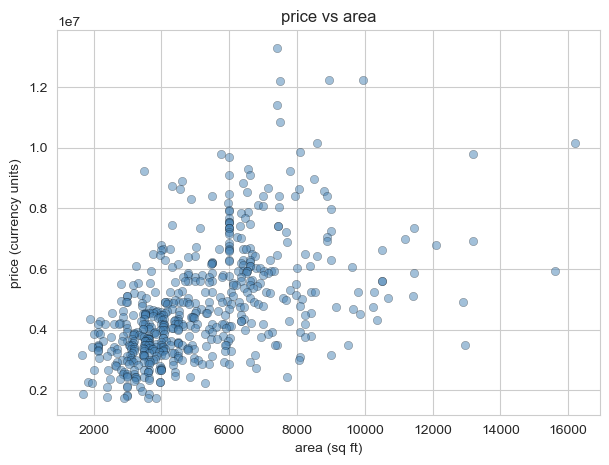

Correlation between area and price: 0.536


In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(df[FEATURE], df[TARGET], alpha=0.5, color="steelblue", edgecolor="k", linewidth=0.3)
plt.title(f"{TARGET} vs {FEATURE}")
plt.xlabel(f"{FEATURE} ({UNIT_FEATURE})")
plt.ylabel(f"{TARGET} ({UNIT_TARGET})")
plt.show()

corr = df[FEATURE].corr(df[TARGET])
print(f"Correlation between {FEATURE} and {TARGET}: {corr:.3f}")

## Step 5: Split the Data into Training and Testing Sets (80:20)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Total observations   :", len(X))
print("Training observations:", len(X_train), f"({len(X_train)/len(X)*100:.0f}%)")
print("Testing observations :", len(X_test),  f"({len(X_test)/len(X)*100:.0f}%)")

Total observations   : 545
Training observations: 436 (80%)
Testing observations : 109 (20%)


## Step 6: Train the Linear Regression Model
Intercept, slope and model equation

In [13]:
model = LinearRegression()
model.fit(X_train, y_train)      # training data only; the test set is never used here

intercept = model.intercept_
slope = model.coef_[0]

print("Intercept (b0):", round(intercept, 4))
print("Coefficient / slope (b1):", round(slope, 4))
print(f"\nModel equation:  {TARGET} = {intercept:.4f} + {slope:.4f} x {FEATURE}")

Intercept (b0): 2512254.264
Coefficient / slope (b1): 425.7298

Model equation:  price = 2512254.2640 + 425.7298 x area


## Step 7: Predictions on the Test Set
Actual vs predicted values side by side

In [14]:
y_pred = model.predict(X_test)      # predictions for TEST inputs only

comparison = pd.DataFrame({
    FEATURE: X_test[FEATURE].values,
    "Actual": y_test.values,
    "Predicted": y_pred.round(2),
})
comparison["Error (Actual - Predicted)"] = (comparison["Actual"] - comparison["Predicted"]).round(2)

print("Sample of 10 test records:")
display(comparison.head(10))

Sample of 10 test records:


,area,Actual,Predicted,Error (Actual - Predicted)
0,5900,4060000,5024060.33,-964060.33
1,6500,6650000,5279498.24,1370501.76
2,4040,3710000,4232202.83,-522202.83
3,5000,6440000,4640903.47,1799096.53
4,3960,2800000,4198144.44,-1398144.44
5,6720,4900000,5373158.80,-473158.80
6,8520,5250000,6139472.52,-889472.52
7,4990,4543000,4636646.18,-93646.18
8,3240,2450000,3891618.95,-1441618.95
9,2700,3353000,3661724.84,-308724.84


## Step 8: Evaluate the Model (MAE, MSE, RMSE, R²)

In [15]:
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print(f"MAE  : {mae:,.4f}")
print(f"MSE  : {mse:,.4f}")
print(f"RMSE : {rmse:,.4f}")
print(f"R2   : {r2:.4f}")

print("\nFor context:")
print(f"Average actual price (test): {y_test.mean():,.2f}")
print(f"MAE as % of average price  : {mae / y_test.mean() * 100:.1f}%")

MAE  : 1,474,748.1338
MSE  : 3,675,286,604,768.1851
RMSE : 1,917,103.7021
R2   : 0.2729

For context:
Average actual price (test): 5,007,536.70
MAE as % of average price  : 29.5%


### 8.1 Compare Training R² and Testing R² (Overfitting Check)

In [16]:
# Optional: compare train and test R2 to check for overfitting
r2_train = r2_score(y_train, model.predict(X_train))
print(f"R2 on training data: {r2_train:.4f}")
print(f"R2 on test data    : {r2:.4f}")

R2 on training data: 0.2850
R2 on test data    : 0.2729


## Step 9: Visualise Actual vs Predicted Values

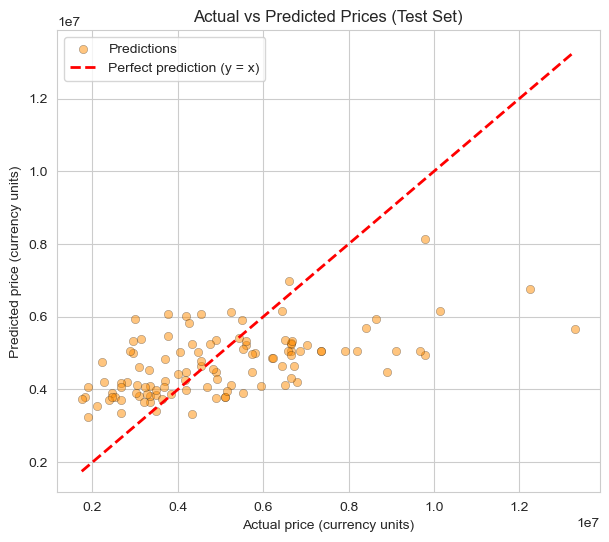

In [17]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color="darkorange", edgecolor="k", linewidth=0.3, label="Predictions")

lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", linewidth=2, label="Perfect prediction (y = x)")

plt.title("Actual vs Predicted Prices (Test Set)")
plt.xlabel(f"Actual {TARGET} ({UNIT_TARGET})")
plt.ylabel(f"Predicted {TARGET} ({UNIT_TARGET})")
plt.legend()
plt.show()

### 9.1 Regression Line on Test Data

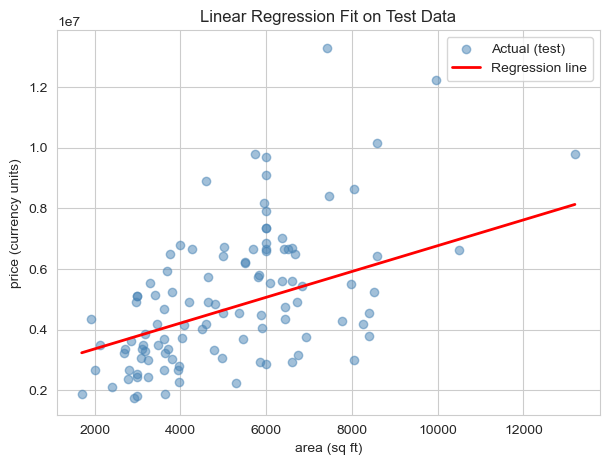

In [18]:
# Bonus: regression line over the data
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, alpha=0.5, color="steelblue", label="Actual (test)")
plt.plot(X_test.sort_values(FEATURE), model.predict(X_test.sort_values(FEATURE)),
         color="red", linewidth=2, label="Regression line")
plt.title("Linear Regression Fit on Test Data")
plt.xlabel(f"{FEATURE} ({UNIT_FEATURE})")
plt.ylabel(f"{TARGET} ({UNIT_TARGET})")
plt.legend()
plt.show()

## Step 10: Predict a New Example

In [19]:
# Choose a value within the range of the training data
print(f"{FEATURE} range in training data: {X_train[FEATURE].min()} to {X_train[FEATURE].max()}")

new_value = float(X_train[FEATURE].median())   # <-- or type your own, e.g. 5000
new_input = pd.DataFrame({FEATURE: [new_value]})

new_prediction = model.predict(new_input)[0]
print(f"\nFor {FEATURE} = {new_value} {UNIT_FEATURE}")
print(f"Predicted {TARGET} = {new_prediction:,.2f} {UNIT_TARGET}")

area range in training data: 1650 to 16200

For area = 4500.0 sq ft
Predicted price = 4,428,038.55 currency units


## Conclusion

**Dataset and target/feature selection.** I used the Housing Prices dataset (`Housing.csv`, CSV format; source link: *add your link here*). It has 545 rows and 13 columns, where each row is one house with its price and features such as area, bedrooms, bathrooms, stories and parking. The target is `price`, a continuous numerical column. The input feature is `area`, because a bigger house generally has more built-up space and rooms, which usually raises its price.

**Data quality.** I found no missing values and no duplicate rows, and no price or area was zero or negative, so no rows needed to be dropped or filled. The scatter plot showed a positive relationship between area and price, with a correlation of 0.536, which is moderate. This does not prove that area *causes* the price to change, since other factors such as location and amenities are also involved.

**Train-test split and model.** The data was split 80:20 into 436 training records and 109 testing records, with `random_state=42` so the split is repeatable. The test set was kept unseen during training. Linear Regression learned this equation:

`price = 2,512,254.26 + 425.73 × area`

The slope means that for each extra square foot of area, the predicted price rises by about 425.73 currency units. The intercept (about 2.51 million) is the predicted price when area is 0. It is only a mathematical starting point, not a real house.

**Evaluation.** On the test set the model gave MAE = 1,474,748, MSE = 3.68 × 10¹², RMSE = 1,917,104 and R² = 0.273.
- The typical error (MAE) is about 1.47 million, which is about 29.5% of the average test price (about 5.0 million), so the predictions are often far from the actual prices.
- R² = 0.273 means area alone explains only about 27% of the variation in price. The remaining 73% is due to factors the model does not see.
- Training R² (0.285) and testing R² (0.273) are very close, so the model is not overfitting. It is underfitting, because a single feature is too simple for this problem.
- In the sample of test records, some houses were under-predicted by more than 1.3 million and others over-predicted by more than 1.4 million. For example, a house with area 5,000 sq ft sold for 6.44 million but was predicted at about 4.64 million. This agrees with the wide spread of points around the perfect-prediction line in the actual vs predicted plot.

**New prediction.** For a new house with area = 4,500 sq ft (inside the training range of 1,650 to 16,200), the model predicts a price of about 4,428,039 currency units.

**Limitations and improvements.** House prices depend on many things, such as the number of bathrooms and stories, parking, air conditioning, location and furnishing, and a one-feature straight-line model cannot capture all of them. The model also assumes a linear relationship, and extreme values (very large or expensive houses) can pull the line. The model could be improved by using multiple features (multiple linear regression), encoding the yes/no and categorical columns, and trying models that handle non-linear patterns.
